# 15 · Soil-moisture retrieval: events, gradients and dielectric inversion

**2026-10-15 coefficient correction:** embedded outputs below predate the reviewed Hallikainen tables/texture units and texture-aware Dobson variant. They are retained as historical outputs; rerun all cells to regenerate. See [source audit and new real-point comparisons](../../MiaplPy/docs/dielectric_model_review_20261015.md).

A reproducible companion to [NavaSAR's retrieval guide](../docs/soil_moisture_retrieval.md).

**What this notebook does**
1. Compare the published exponential-event SMI and normalized-gradient proxy.
2. Demonstrate robust event fitting as a numerical extension, not a novelty claim.
3. Run separate, explicitly synthetic Hallikainen/Dobson/Wang–Schmugge closure inversions.
4. Inspect the previously saved real east–west point results without changing them.

Synthetic truth is known only in sections 2–4. Real SMI is relative and branch-conditional. No raw SLC processing, Slurm submission, full-raster inversion, or automatic absolute-moisture calibration occurs here.

Requirements: NumPy, SciPy, Matplotlib, h5py and a Python Jupyter kernel. Choose your **sp** kernel in Jupyter/VS Code. The setup prints the actual interpreter and source location. Figures are saved as vector PDF and 400-dpi PNG in a new timestamped directory.


In [1]:
import sys
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import h5py
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Find the source checkout whether launched from the project or notebooks folder.
roots = [p / suffix for p in (Path.cwd(), *Path.cwd().parents)
         for suffix in ("", "NavaSAR")]
REPO = next((p for p in roots if (p / "navasar/zheng_retrieval.py").is_file()), None)
if REPO is None:
    raise RuntimeError("Launch Jupyter inside the NavaSAR checkout/project.")
sys.path.insert(0, str(REPO))
import navasar
from navasar import retrieve_smi, event_response, normalize_smi, closure_phase_from_ifgrams
from navasar.dielectric_inversion import (
    dielectric_covariance, invert_closure_moisture, triangle_closure, MODEL_NOTES,
)

OUT = REPO / "examples/15_soil_moisture_retrieval" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUT.mkdir(parents=True, exist_ok=False)
print("Python:", sys.executable)
print("NavaSAR:", navasar.__file__)
print("Output:", OUT)
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "pdf.fonttype": 42,
                     "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
COLORS = ["#0072B2", "#D55E00", "#009E73"]
def save_show(fig, name):
    for suffix in ("png", "pdf"):
        fig.savefig(OUT / f"{name}.{suffix}", dpi=400, bbox_inches="tight")
    plt.show()
    plt.close(fig)


Python: /tmp/soil-review-conda/bin/python
NavaSAR: /raid2-gpu2/maref/Thesis_final_project/NavaSAR/navasar/__init__.py
Output: /raid2-gpu2/maref/Thesis_final_project/NavaSAR/examples/15_soil_moisture_retrieval/20261015_005344_109816


## 1. Which model does what?

| Approach | Role | Attribution |
|---|---|---|
| Event SMI | Fits saturating closure steps, reconstructs decaying moisture events | Zheng & Fattahi, Eqs. 10–11 |
| Normalized gradient | Differentiates filtered closure and normalizes it | Zheng & Fattahi, §6.1 |
| Robust event fitting | Same event equations, soft-L1 residual loss | Our implementation variant of established robust optimization |
| Hallikainen / Dobson / Wang–Schmugge | Map trial moisture and soil parameters to permittivity | Dielectric forward models, not standalone retrieval algorithms |

The current Event SMI implements the **published equations**, not an exact copy of the authors' optimizer, event selection or spatial-unwrapping workflow. Gradient SMI is **not our invention**. Robust loss and direct closure inversion also have prior art.

For event onset $t_i$, closure amplitude $\beta_i$ and decay time $\omega_i$:

$$c(t)=c_0+\sum_i\beta_i(1-e^{-(t-t_i)/\omega_i})H(t-t_i).$$

With the paper's simplifying choice $A=\lambda=1$:

$$x(t)=\sum_i\frac{\beta_i}{\omega_i}e^{-(t-t_i)/\omega_i}H(t-t_i),
\qquad \mathrm{SMI}(t)=\frac{x(t)-\min x}{\max x-\min x}.$$

Signed events allow wetting and drying. Min–max normalization is not clipping; it does not recover absolute moisture.


## 2. Known-equation recovery: irregular dates and an outlier

This is an **inverse-equation test**, not a dielectric/SLC simulation and not field data. We generate three known signed events, remove acquisition dates, add noise and one outlier. Compare event fitting, robust fitting and the gradient proxy without assuming a universal winner.

The optimizer selects event count using BIC. Onset neighborhoods and bounds are implementation choices. The temporal median filter uses three acquisitions, not a fixed number of days.


Selected events: 3 (ordinary), 3 (robust)
Normalized-index RMSE: {
  "Event SMI": 0.10655315816094356,
  "Robust event": 0.10598709597936648,
  "Gradient proxy": 0.07583280202787804
}


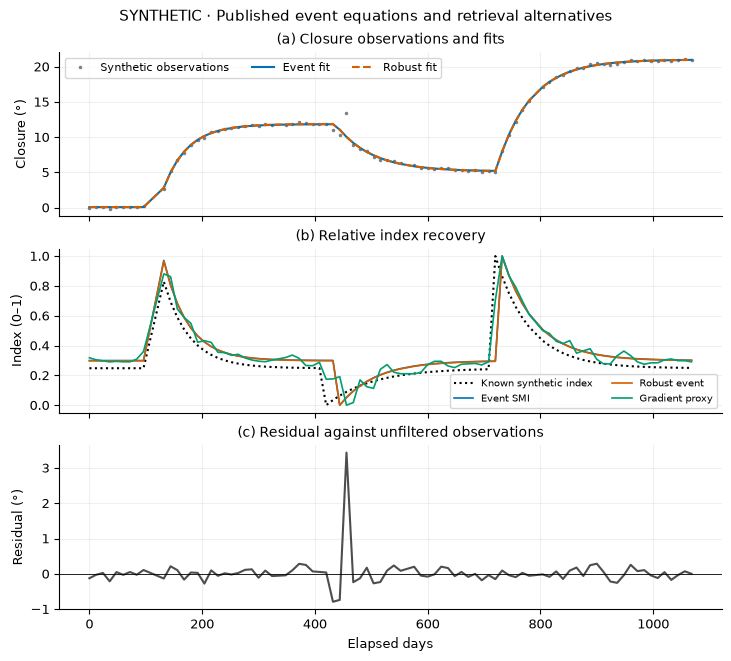

In [2]:
days = np.delete(np.arange(90, dtype=float) * 12, [9, 10, 28, 47, 66])
closure_true, precursor_true = event_response(
    days, [12., -7., 16.], [45., 80., 60.], [120., 420., 720.])
rng = np.random.default_rng(31)
closure_observed = closure_true + rng.normal(0, .15, len(days))
closure_observed[35] += 4.
standard = retrieve_smi(days, closure_observed)
robust = retrieve_smi(days, closure_observed, loss="soft_l1")
truth_index = normalize_smi(precursor_true)
estimates = {"Event SMI": standard["event_smi"],
             "Robust event": robust["event_smi"],
             "Gradient proxy": standard["gradient_smi"]}
metrics = {name: float(np.sqrt(np.mean((values - truth_index)**2)))
           for name, values in estimates.items()}
print("Selected events:", standard["event_count"], "(ordinary),",
      robust["event_count"], "(robust)")
print("Normalized-index RMSE:", json.dumps(metrics, indent=2))

fig, axes = plt.subplots(3, 1, figsize=(7.2, 6.5), sharex=True, layout="constrained")
axes[0].plot(days, closure_observed, ".", color=".5", ms=3, label="Synthetic observations")
axes[0].plot(days, standard["closure_fit"], color=COLORS[0], label="Event fit")
axes[0].plot(days, robust["closure_fit"], "--", color=COLORS[1], label="Robust fit")
axes[0].set(title="(a) Closure observations and fits", ylabel="Closure (°)")
axes[0].legend(fontsize=8, ncol=3)
axes[1].plot(days, truth_index, "k:", label="Known synthetic index")
for (name, values), color in zip(estimates.items(), COLORS):
    axes[1].plot(days, values, color=color, label=name, lw=1.2)
axes[1].set(title="(b) Relative index recovery", ylabel="Index (0–1)", ylim=(-.05, 1.05))
axes[1].legend(fontsize=7, ncol=2)
axes[2].plot(days, closure_observed - standard["closure_fit"], color=".3")
axes[2].axhline(0, color="k", lw=.6)
axes[2].set(title="(c) Residual against unfiltered observations",
            ylabel="Residual (°)", xlabel="Elapsed days")
fig.suptitle("SYNTHETIC · Published event equations and retrieval alternatives")
save_show(fig, "fig01_event_gradient_comparison")


## 3. Controls: zero information and wrapped-phase branches

A BW1 chain has no loops. Closure needs additional edges. A zero-closure phase ramp can still produce a large false network difference if principal wrapped angles are directly used in linear least squares.

`branch="bw1"` lifts pair phases to the nearest BW1-predicted branch. It fixes this particular control but is **not spatial unwrapping** and does not guarantee the right branch on real data. No-information output remains flagged rather than filled with artificial moisture.


Zero-information status: no_resolved_closure
BW1-guided maximum closure (degrees): 1.0177774980683254e-12


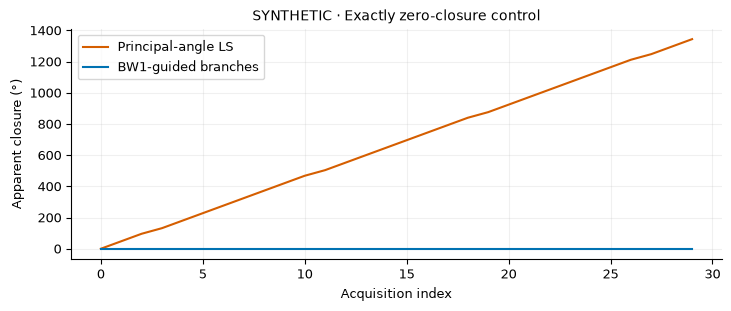

In [3]:
phase = np.arange(30) * .8
I_control = np.exp(1j * (phase[None, :] - phase[:, None]))
cp_principal = closure_phase_from_ifgrams(I_control, branch="principal")[0]
cp_bw1 = closure_phase_from_ifgrams(I_control, branch="bw1")[0]
no_signal = retrieve_smi(np.arange(30.), np.zeros(30))
assert np.max(np.abs(cp_bw1)) < 1e-8
assert no_signal["status"] == "no_resolved_closure"
assert np.isnan(no_signal["event_smi"]).all()
print("Zero-information status:", no_signal["status"])
print("BW1-guided maximum closure (degrees):", np.max(np.abs(cp_bw1)))
fig, ax = plt.subplots(figsize=(7.2, 3), layout="constrained")
ax.plot(cp_principal, label="Principal-angle LS", color=COLORS[1])
ax.plot(cp_bw1, label="BW1-guided branches", color=COLORS[0])
ax.set(title="SYNTHETIC · Exactly zero-closure control",
       xlabel="Acquisition index", ylabel="Apparent closure (°)")
ax.legend()
save_show(fig, "fig02_branch_control")


## 4. Dielectric models **inside** an inversion

Now solve a different inverse problem:

$$\mathbf m\rightarrow\epsilon(\mathbf m)\rightarrow k_i
\rightarrow C_{ij}\rightarrow\arg(C_{ij}C_{jk}C_{ki}).$$

The added experimental API uses uniform semi-infinite scattering and fits circular triangle residuals, fixing the first acquisition to a supplied moisture reference. It returns bounds, data-Jacobian rank and multistart spread.

**Important:** this section is a noise-free **same-model numerical self-consistency test**. Each model generates its own observations and then inverts them. It cannot determine which dielectric model is physically best. The known reference 0.10 is synthetic truth, not a suggested field calibration.

Limitations retained from local implementations:
- Hallikainen now uses verified percent-weight texture and 1.4–18 GHz tables, with adjacent interpolation. The old embedded results below used incorrect texture units and a mislabeled frequency row.
- The wrapper now uses the texture-aware Ulaby/Dobson-family variant. Legacy behari.dobson_semiemp remains texture-independent.
- Wang–Schmugge includes texture but uses assumed density, temperature and empirical loss parameters.

Explicit `allow_experimental=True` acknowledges these limitations. No real points are inverted here.


hallikainen conditional_fit closure RMSE (deg) = 0.00385 multistart spread = 0.32737 Jacobian rank = 7 / 7
  Local coefficient texture convention needs verification; only 1.4 and 5 GHz tables.


dobson conditional_fit closure RMSE (deg) = 0.00291 multistart spread = 0.43925 Jacobian rank = 7 / 7
  Local simplified Dobson ignores its sand/clay arguments; NOT texture-corrected Dobson.


wang-schmugge conditional_fit closure RMSE (deg) = 0.00239 multistart spread = 0.4331 Jacobian rank = 7 / 7
  Local empirical implementation with assumed density, temperature and loss parameters.


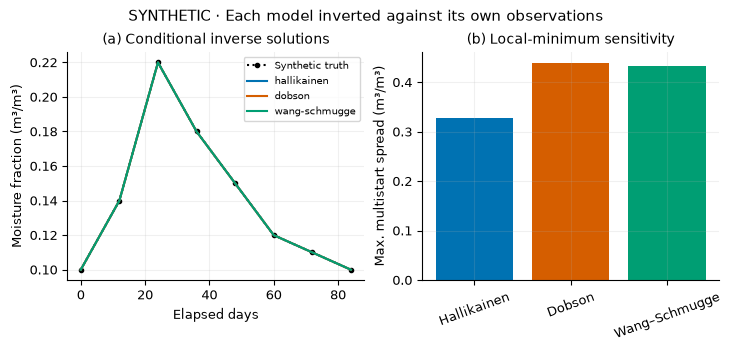

In [4]:
moisture_true = np.array([.10, .14, .22, .18, .15, .12, .11, .10])
model_days = np.arange(len(moisture_true), dtype=float) * 12
model_results = {}
for name in MODEL_NOTES:
    kw = dict(model=name, frequency_ghz=5.0, sand=.51, clay=.13,
              allow_experimental=True)
    simulated_covariance = dielectric_covariance(moisture_true, **kw)
    result = invert_closure_moisture(
        simulated_covariance, model_days, reference_moisture=moisture_true[0],
        starts=12, max_nfev=300, **kw)
    model_results[name] = result
    print(name, result["status"],
          "closure RMSE (deg) =", round(result["closure_rmse_deg"], 5),
          "multistart spread =", round(result["multistart_max_spread"], 5),
          "Jacobian rank =", result["data_jacobian_rank"], "/", result["unknowns"])
    print(" ", result["model_note"])

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4), layout="constrained")
axes[0].plot(model_days, moisture_true, "k:o", ms=3, label="Synthetic truth")
for (name, r), color in zip(model_results.items(), COLORS):
    axes[0].plot(model_days, r["moisture"], color=color, label=name)
axes[0].set(title="(a) Conditional inverse solutions",
            xlabel="Elapsed days", ylabel="Moisture fraction (m³/m³)")
axes[0].legend(fontsize=7)
labels = ["Hallikainen", "Dobson", "Wang–Schmugge"]
axes[1].bar(labels, [r["multistart_max_spread"] for r in model_results.values()], color=COLORS)
axes[1].tick_params(axis="x", labelrotation=20)
axes[1].set(title="(b) Local-minimum sensitivity", ylabel="Max. multistart spread (m³/m³)")
fig.suptitle("SYNTHETIC · Each model inverted against its own observations")
save_show(fig, "fig03_dielectric_inverse_tests")


## 5. Optional inspection of saved real east–west results

This section only **reads** the completed point-product file from the Mina project. It never reads the large raw SLC stack or starts a new inversion. Set `LOAD_REAL_RESULTS=False` to skip it, or change `REAL_FILE` to your own product.

The saved curves are Event SMI, gradient proxy and robust Event SMI—not Hallikainen/Dobson/Wang moisture estimates. Each point is normalized separately. Equal indices at two points do not establish equal absolute moisture. East/west are geographic labels, not verified rainfall regimes. Branch differences are printed because the existing phase branches remain a scientific limitation.


READ-ONLY source: /raid2-gpu2/maref/Thesis_final_project/MiaplPy/results/zheng_paper_real_20261015_003741/east_west_points.h5
Dates: 79 points: 6
east_4 maximum branch difference (deg): 1353.42
east_5 maximum branch difference (deg): 1321.52
east_6 maximum branch difference (deg): 496.71
west_1 maximum branch difference (deg): 1139.24
west_2 maximum branch difference (deg): 2761.52
west_3 maximum branch difference (deg): 2160.0


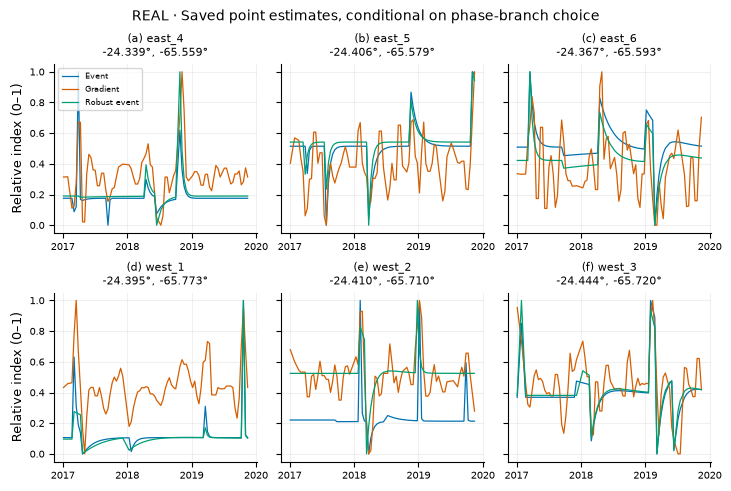

In [5]:
LOAD_REAL_RESULTS = True
REAL_FILE = (REPO.parent / "MiaplPy/results/zheng_paper_real_20261015_003741/east_west_points.h5")
real = {}
if LOAD_REAL_RESULTS and REAL_FILE.is_file():
    with h5py.File(REAL_FILE, "r") as f:
        real_dates = [datetime.strptime(d.decode() if isinstance(d, bytes) else str(d), "%Y%m%d")
                      for d in f["date"][...]]
        for name in sorted(k for k in f if k.startswith(("west_", "east_"))):
            g = f[name]
            real[name] = {key: g[key][...] for key in
                          ("event_smi", "gradient_smi", "robust_event_smi",
                           "closure_bw1_branch_deg", "closure_principal_deg")}
            real[name].update(latitude=float(g.attrs["latitude"]),
                              longitude=float(g.attrs["longitude"]))
    print("READ-ONLY source:", REAL_FILE)
    print("Dates:", len(real_dates), "points:", len(real))
    for name, r in real.items():
        discrepancy = np.max(np.abs(r["closure_bw1_branch_deg"] - r["closure_principal_deg"]))
        print(name, "maximum branch difference (deg):", round(float(discrepancy), 2))
else:
    print("Real-data inspection skipped. Synthetic results above remain available.")

if real:
    fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.8), sharey=True, layout="constrained")
    for index, (ax, (name, r)) in enumerate(zip(axes.flat, real.items())):
        for key, color, label in zip(
            ("event_smi", "gradient_smi", "robust_event_smi"), COLORS,
            ("Event", "Gradient", "Robust event")):
            ax.plot(real_dates, r[key], color=color, label=label, lw=.9)
        ax.set_title(f"({chr(97+index)}) {name}\n{r['latitude']:.3f}°, {r['longitude']:.3f}°", fontsize=8)
        ax.set_ylim(-.05, 1.05)
        locator = mdates.AutoDateLocator(minticks=3, maxticks=4)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        ax.tick_params(labelsize=7)
    for ax in list(axes.flat)[len(real):]:
        ax.set_visible(False)
    axes[0, 0].legend(fontsize=6)
    axes[0, 0].set_ylabel("Relative index (0–1)")
    axes[1, 0].set_ylabel("Relative index (0–1)")
    fig.suptitle("REAL · Saved point estimates, conditional on phase-branch choice", fontsize=10)
    save_show(fig, "fig04_real_point_indices")


## 6. Interpretation and provenance

- A good synthetic equation fit verifies numerical behavior, not the physical model.
- A small closure residual does not establish unique or correct absolute moisture.
- Robust loss may help with outliers but can suppress genuine sharp events.
- Multiple starts are necessary here; they do not guarantee a global solution.
- Correct radar geolocation is necessary for texture sampling. Shape resizing is not geolocation.
- None of these experiments establishes scientific novelty.

The cell below saves the synthetic arrays and metrics separately from the original field product. It also records the inspected real-product path, if any. Existing field products are never overwritten.

### References
- [Zheng & Fattahi (2026)](https://doi.org/10.1016/j.rse.2025.115104): event equations and normalized-gradient proxy.
- [De Zan & Gomba (2018)](https://elib.dlr.de/121676/): prior closure-phase moisture inversion.
- [SciPy least_squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html): established robust fitting.
- [Detailed NavaSAR method guide](../docs/soil_moisture_retrieval.md).


In [6]:
with h5py.File(OUT / "synthetic_notebook_results.h5", "w") as f:
    f.attrs["source"] = "synthetic; NOT field moisture"
    f["time_days"] = days
    f["closure_observed_deg"] = closure_observed
    f["truth_index"] = truth_index
    for name, values in estimates.items():
        f[name.replace(" ", "_")] = values
    g = f.create_group("dielectric_inverse_tests")
    g["time_days"] = model_days
    g["truth_moisture"] = moisture_true
    for name, r in model_results.items():
        group = g.create_group(name)
        group["conditional_moisture"] = r["moisture"]
        for key in ("closure_rmse_deg", "multistart_max_spread", "data_jacobian_rank"):
            group.attrs[key] = r[key]
provenance = {
    "python": sys.executable, "navasar_source": str(navasar.__file__),
    "synthetic_index_rmse": metrics,
    "real_product_inspected_read_only": str(REAL_FILE) if real else None,
    "real_points": list(real),
    "note": "No new real dielectric inversion or absolute calibration performed.",
}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2))
print("Finished. Figures, synthetic HDF5 and provenance:", OUT)


Finished. Figures, synthetic HDF5 and provenance: /raid2-gpu2/maref/Thesis_final_project/NavaSAR/examples/15_soil_moisture_retrieval/20261015_005344_109816
